# Population Density

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df= pd.read_excel("ONS population density.xlsx")
print("Dataset shape:", df.shape)
df = df.rename(columns={"Lower layer Super Output Areas Code": "LSOA_code"})
df.head()

Dataset shape: (35672, 3)


,LSOA_code,Lower layer Super Output Areas,Observation
0,E01000001,City of London 001A,11363.6
1,E01000002,City of London 001B,6062.2
2,E01000003,City of London 001C,27385.4
3,E01000005,City of London 001E,5801.7
4,E01000006,Barking and Dagenham 016A,12585.3


# Data Cleaning

In [2]:
#removes all leading and trailing whitespace from the column names
df.columns = df.columns.str.strip()

In [3]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicates:", df.duplicated().sum())
print("Unique LSOAs:", df["LSOA_code"].nunique())

Missing values: 0
Duplicates: 0
Unique LSOAs: 35672


In [5]:
# Create a copy
pop_density = df.copy()

# Remove accidental whitespace from text columns
pop_density["LSOA_code"] = pop_density["LSOA_code"].astype(str).str.strip()
pop_density["Lower layer Super Output Areas"] = (
    pop_density["Lower layer Super Output Areas"]
    .astype(str)
    .str.strip()
)

# Ensure population density is numeric
pop_density["Observation"] = pd.to_numeric(
    pop_density["Observation"],
    errors="coerce"
)

In [8]:
print(pop_density.isnull().sum())

# Check duplicate LSOAs
print("Duplicate LSOA codes:",
      pop_density["LSOA_code"].duplicated().sum())

# Check impossible/non-positive values
print("Non-positive population density:",
      (pop_density["Observation"] <= 0).sum())

LSOA_code                         0
Lower layer Super Output Areas    0
Observation                       0
dtype: int64
Duplicate LSOA codes: 0
Non-positive population density: 0


Very high densities can legitimately occur in densely populated urban LSOAs, particularly in London.

# EDA

In [9]:
# Descriptive statistics
print(pop_density["Observation"].describe())

count     35672.000000
mean       4403.437719
std        4606.439322
min           2.300000
25%        1206.100000
50%        3494.750000
75%        5830.500000
max      115567.000000
Name: Observation, dtype: float64


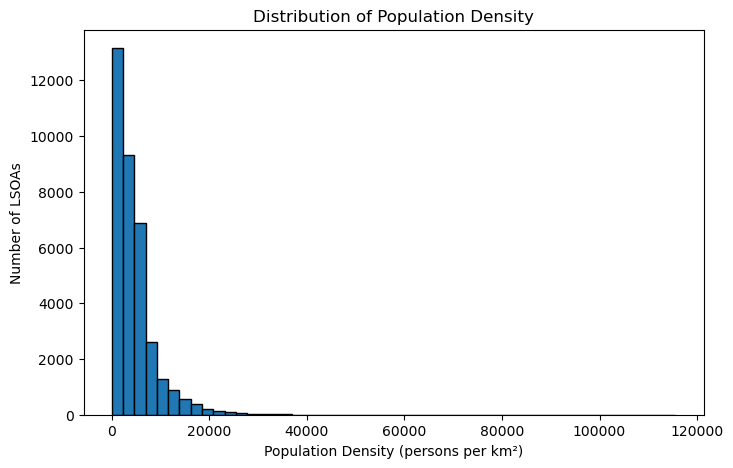

In [11]:
#Distribution
plt.figure(figsize=(8, 5))

plt.hist(
    pop_density["Observation"],
    bins=50,
    edgecolor="black"
)

plt.xlabel("Population Density (persons per km²)")
plt.ylabel("Number of LSOAs")
plt.title("Distribution of Population Density")

plt.show()

Graph shows that distribution is strongly right-skewed because a relatively small number of dense urban LSOAs have much higher population densities.

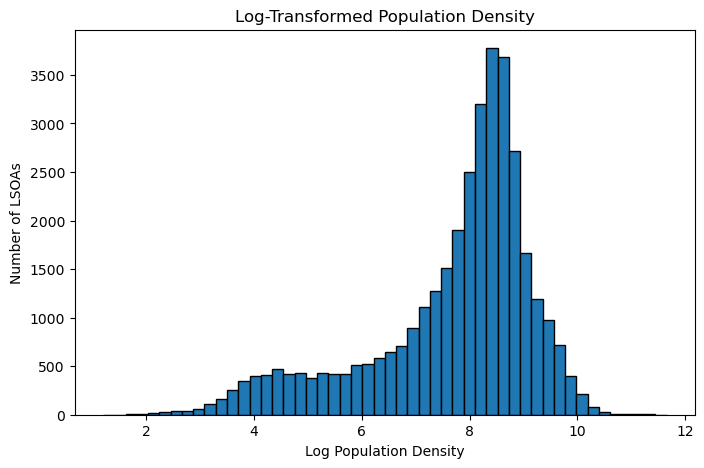

In [12]:
plt.figure(figsize=(8, 5))

plt.hist(
    np.log1p(pop_density["Observation"]),
    bins=50,
    edgecolor="black"
)

plt.xlabel("Log Population Density")
plt.ylabel("Number of LSOAs")
plt.title("Log-Transformed Population Density")

plt.show()

The logarithmic transformation compresses the original heavily right-skewed population density data into a much more symmetric, bell-like curve suitable for statistical modeling. The main peak centered around 8.4–8.6 represents the vast majority of LSOAs, which correspond to typical urban and suburban population densities across England.

# Feature Engineering

In [15]:
#log population Density
pop_density["population_density_log"] = np.log1p(pop_density["Observation"]
)

Since normal population density is heavily skewed to right. This is useful for modelling because it reduces the influence of extremely dense LSOAs without deleting.

In [16]:
pop_density[
        [
            "LSOA_code",
            "Observation",
            "population_density_log"
        ]
    ].head()

,LSOA_code,Observation,population_density_log
0,E01000001,11363.6,9.338259
1,E01000002,6062.2,8.709993
2,E01000003,27385.4,10.217802
3,E01000005,5801.7,8.666079
4,E01000006,12585.3,9.440364


In [18]:
population_features = pop_density[
    [
        "LSOA_code",
        "Observation",
        "population_density_log"
    ]
].copy()

The dataset was cleaned and transformed and then the selected features were then saved into a new dataset as shown below

In [19]:
population_features.to_excel(
    "popdensity_features.xlsx",
    index=False
)